# 21 — Reproducing a README Chart

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

The README shows five charts in the `images/` folder. Four of them are copies of charts drawn in notebooks 01, 12, 17
and 20, so running those notebooks draws them again. The fifth chart, `images/04_day30_feature_experiments.png`,
combines results from **three** notebooks (14, 15 and 16), so no single notebook draws it.

This notebook contains the code for that chart. It does **not** train models or load the XES data: it only uses the
verified results that notebooks 14–16 printed.

## 2. The Values and Where They Come From

Each row is one Logistic Regression feature set for the day-30 problem. The numbers are the ROC-AUC values from the
comparison tables of the executed notebooks (rounded to 3 decimals):

- `cv_mean` and `cv_std`: mean and standard deviation over the 5 cross-validation folds;
- `random_test`: the random test (161 cases);
- `temporal_test`: the temporal test (168 newer cases).

In [1]:
import io
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

In [2]:
results = pd.DataFrame([
    {"variant": "A. Original", "source": "notebook 14, section 12", "cv_mean": 0.702, "cv_std": 0.033, "random_test": 0.659, "temporal_test": 0.678},
    {"variant": "B. Activity groups", "source": "notebook 14, section 12", "cv_mean": 0.694, "cv_std": 0.034, "random_test": 0.680, "temporal_test": 0.709},
    {"variant": "C. Original + groups", "source": "notebook 14, section 12", "cv_mean": 0.710, "cv_std": 0.017, "random_test": 0.708, "temporal_test": 0.705},
    {"variant": "D. PCA, 10 comp.", "source": "notebook 15, section 12", "cv_mean": 0.709, "cv_std": 0.036, "random_test": 0.721, "temporal_test": 0.729},
    {"variant": "E. C + TF-IDF text", "source": "notebook 16, section 14", "cv_mean": 0.702, "cv_std": 0.033, "random_test": 0.725, "temporal_test": 0.657},
])
results

,variant,source,cv_mean,cv_std,random_test,temporal_test
0,A. Original,"notebook 14, section 12",0.702,0.033,0.659,0.678
1,B. Activity groups,"notebook 14, section 12",0.694,0.034,0.680,0.709
2,C. Original + groups,"notebook 14, section 12",0.710,0.017,0.708,0.705
3,"D. PCA, 10 comp.","notebook 15, section 12",0.709,0.036,0.721,0.729
4,E. C + TF-IDF text,"notebook 16, section 14",0.702,0.033,0.725,0.657


The chart labels add the notebook each variant comes from (A is the original model of notebooks 10–12, reproduced in
notebook 14).

In [3]:
labels = [
    "A. Original\n(notebooks 10-12)",
    "B. Activity groups\n(notebook 14)",
    "C. Original + groups\n(notebook 14)",
    "D. PCA, 10 comp.\n(notebook 15)",
    "E. C + TF-IDF text\n(notebook 16)",
]

## 3. Draw the Chart

The same grouped bar chart as in notebooks 12–17: the black error bars show **±1 standard deviation across the five
folds** (not a confidence interval), and the dashed line is the majority baseline (0.50).

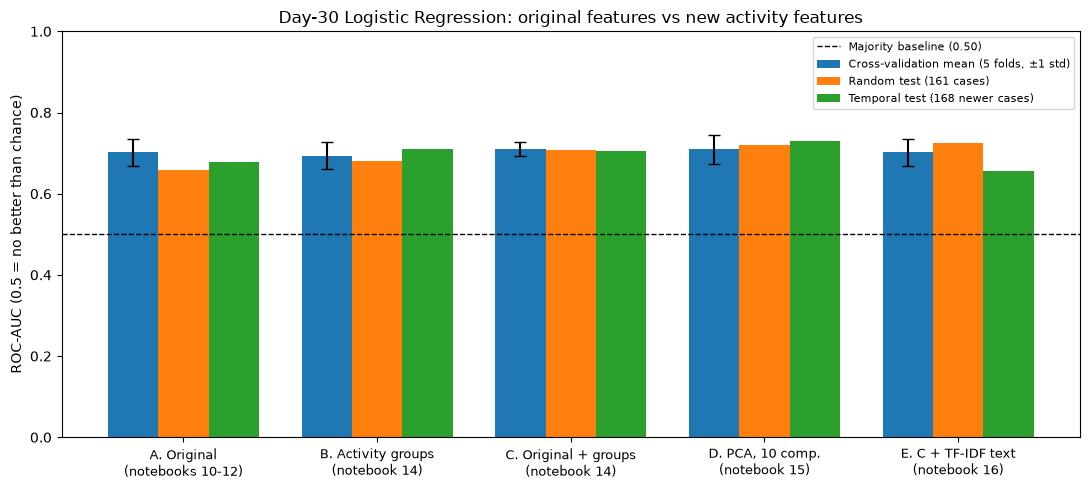

In [4]:
positions = list(range(len(results)))
width = 0.26

figure = plt.figure(figsize=(11, 5))
plt.bar([p - width for p in positions], results["cv_mean"], width,
        yerr=results["cv_std"], capsize=4, label="Cross-validation mean (5 folds, ±1 std)")
plt.bar(positions, results["random_test"], width, label="Random test (161 cases)")
plt.bar([p + width for p in positions], results["temporal_test"], width, label="Temporal test (168 newer cases)")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1, label="Majority baseline (0.50)")
plt.xticks(positions, labels, fontsize=9)
plt.ylim(0, 1)
plt.ylabel("ROC-AUC (0.5 = no better than chance)")
plt.title("Day-30 Logistic Regression: original features vs new activity features")
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

## 4. Save or Compare with the README Image

- If `images/04_day30_feature_experiments.png` does **not** exist yet, the chart is saved there.
- If it **already exists**, it is **not overwritten**. Instead, the new chart is saved into memory (`io.BytesIO`) and
  compared with the existing file.

**Two kinds of "the same":** a **visual reproduction** means the chart shows the same values, labels and layout. A
**byte-for-byte** match means the PNG files are identical down to the last byte. Different matplotlib versions or
computers can produce slightly different bytes for a chart that looks the same, so a different file does not mean
different results: the values in the table above are what matters.

In [5]:
image_file = project_root / "images" / "04_day30_feature_experiments.png"

new_png = io.BytesIO()
figure.savefig(new_png, format="png", dpi=120)

if image_file.exists():
    same_bytes = new_png.getvalue() == image_file.read_bytes()
    print("The README image already exists and was NOT overwritten.")
    print("Byte-for-byte identical to the new chart:", same_bytes)
else:
    image_file.parent.mkdir(exist_ok=True)
    image_file.write_bytes(new_png.getvalue())
    print("Saved:", image_file.relative_to(project_root))

The README image already exists and was NOT overwritten.
Byte-for-byte identical to the new chart: True


## 5. Notes

- The values come from the executed notebooks 14–16; if those notebooks are changed and re-run, the table above must be
  updated by hand.
- The chart only summarises earlier results. It adds no new model, and all limitations of notebooks 14–16 still apply:
  the test sets were already used before, and the differences between B, C and D are small.